# Driver Drowsiness Detection using OpenCV + Machine Learning

**Environment:** Run this notebook in *local Jupyter Notebook/JupyterLab* on your laptop. It opens a native OpenCV window to use your webcam, so cloud notebooks may not access your local camera.

## Project pipeline
1. Install compatible libraries.
2. Detect facial landmarks with MediaPipe Face Mesh.
3. Calculate eye openness (EAR) and mouth opening (MAR).
4. Collect samples that you label as `Alert` or `Drowsy`.
5. Train and evaluate a Random Forest classifier.
6. Run live detection with an audible warning and event log.

**Important:** This is an educational prototype, not a certified vehicle safety system. Do not test it while driving. For a more realistic evaluation, collect data across multiple sessions and people; samples from adjacent video frames are highly correlated.

## 1. Install dependencies

The following versions are a conservative combination for the legacy `mp.solutions.face_mesh` API used in this notebook. **Python 3.10 or 3.11 is recommended.** If installation fails on a newer Python version, create a Python 3.11 environment and select it as the notebook kernel.

Run this cell once, then restart the kernel if Jupyter asks you to.

In [1]:
%pip install "numpy==1.26.4" "opencv-contrib-python==4.10.0.84" "mediapipe==0.10.21" pandas scikit-learn joblib matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install pygame


Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries and set up project folders

In [3]:
import sys
import time
import threading
from pathlib import Path
from datetime import datetime

import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score

print("Python:", sys.version.split()[0])
print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
LOG_DIR = PROJECT_DIR / "logs"

for folder in (DATA_DIR, MODEL_DIR, LOG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "features.csv"
MODEL_PATH = MODEL_DIR / "drowsiness_model.joblib"
EVENT_LOG_PATH = LOG_DIR / "drowsiness_events.csv"

print("Project folder:", PROJECT_DIR.resolve())

Python: 3.11.18
OpenCV: 4.10.0
MediaPipe: 0.10.21
Project folder: C:\Users\x1605\Mini Project


## 3. Define facial features

- **EAR (Eye Aspect Ratio):** becomes smaller when an eye closes.
- **MAR (Mouth Aspect Ratio):** becomes larger when the mouth opens; this can help flag a possible yawn.
- **Eye-closure duration:** measures how long the eyes remain below the chosen EAR threshold.

The threshold is a starting point, not a universal value. Glasses, lighting, camera angle, and individual faces can affect the measurements.

In [4]:
# MediaPipe Face Mesh landmark indexes for the eye and mouth measurements.
LEFT_EYE = [33, 160, 158, 133, 153, 144]
RIGHT_EYE = [362, 385, 387, 263, 373, 380]
MOUTH_CORNERS = (78, 308)
MOUTH_TOP_BOTTOM = (13, 14)

FEATURE_COLUMNS = [
    "left_ear",
    "right_ear",
    "avg_ear",
    "mar",
    "eye_closed_seconds",
]

EAR_THRESHOLD = 0.21          # Tune for your camera/face after testing
CLOSED_EYE_ALARM_SECONDS = 1.5


def _distance(point_a, point_b):
    """Calculate distance between two MediaPipe facial landmarks."""
    point_a = np.array([point_a.x, point_a.y], dtype=np.float32)
    point_b = np.array([point_b.x, point_b.y], dtype=np.float32)
    return float(np.linalg.norm(point_a - point_b))


def _eye_aspect_ratio(landmarks, indexes):
    p1, p2, p3, p4, p5, p6 = [landmarks[i] for i in indexes]
    horizontal = _distance(p1, p4)
    if horizontal < 1e-8:
        return 0.0
    return (_distance(p2, p6) + _distance(p3, p5)) / (2.0 * horizontal)


def extract_face_metrics(face_landmarks):
    """Return eye and mouth measurements for one detected face."""
    landmarks = getattr(face_landmarks, "landmark", face_landmarks)
    left_ear = _eye_aspect_ratio(landmarks, LEFT_EYE)
    right_ear = _eye_aspect_ratio(landmarks, RIGHT_EYE)
    avg_ear = (left_ear + right_ear) / 2.0

    mouth_top = landmarks[MOUTH_TOP_BOTTOM[0]]
    mouth_bottom = landmarks[MOUTH_TOP_BOTTOM[1]]
    mouth_left = landmarks[MOUTH_CORNERS[0]]
    mouth_right = landmarks[MOUTH_CORNERS[1]]
    mouth_width = _distance(mouth_left, mouth_right)
    mar = _distance(mouth_top, mouth_bottom) / max(mouth_width, 1e-8)

    return {
        "left_ear": float(left_ear),
        "right_ear": float(right_ear),
        "avg_ear": float(avg_ear),
        "mar": float(mar),
    }


class UniversalFaceMesh:
    """Cross-compatible Face Mesh wrapper supporting both legacy mp.solutions and modern Tasks API."""
    def __enter__(self):
        if hasattr(mp, "solutions") and hasattr(mp.solutions, "face_mesh"):
            self.mode = "solutions"
            self.detector = mp.solutions.face_mesh.FaceMesh(
                static_image_mode=False,
                max_num_faces=1,
                refine_landmarks=True,
                min_detection_confidence=0.5,
                min_tracking_confidence=0.5,
            )
        else:
            self.mode = "tasks"
            import urllib.request
            from mediapipe.tasks import python
            from mediapipe.tasks.python import vision
            task_path = Path("models/face_landmarker.task")
            if not task_path.exists():
                task_path.parent.mkdir(parents=True, exist_ok=True)
                url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
                urllib.request.urlretrieve(url, str(task_path))
            base_options = python.BaseOptions(model_asset_path=str(task_path))
            options = vision.FaceLandmarkerOptions(
                base_options=base_options,
                output_face_blendshapes=False,
                output_facial_transformation_matrixes=False,
                num_faces=1,
            )
            self.detector = vision.FaceLandmarker.create_from_options(options)
        return self

    def process(self, rgb_frame):
        if self.mode == "solutions":
            res = self.detector.process(rgb_frame)
            return res.multi_face_landmarks[0] if (res and res.multi_face_landmarks) else None
        else:
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)
            res = self.detector.detect(mp_image)
            return res.face_landmarks[0] if (res and res.face_landmarks and len(res.face_landmarks) > 0) else None

    def __exit__(self, exc_type, exc_val, exc_tb):
        if hasattr(self, "detector") and hasattr(self.detector, "close"):
            self.detector.close()

print("Feature functions and UniversalFaceMesh ready.")

Feature functions ready.


# Adding the Music

In [5]:
from pathlib import Path
import pygame

# Song file ka path
SONG_PATH = Path.cwd() / "funny_munni.mp3"

# Check whether the song file exists
if not SONG_PATH.exists():
    raise FileNotFoundError(
        f"Song file nahi mili: {SONG_PATH}"
    )

# Initialize audio system
pygame.mixer.init()

# Load song
pygame.mixer.music.load(str(SONG_PATH))

print("Song successfully loaded!")

pygame 2.6.1 (SDL 2.28.4, Python 3.11.18)
Hello from the pygame community. https://www.pygame.org/contribute.html
Song successfully loaded!


# Testing the Music

In [6]:
pygame.mixer.music.play()


In [7]:
pygame.mixer.music.stop()

## 4. Test the webcam

Run the cell below. A separate OpenCV window should open. **Click the camera window first** and press **Q** to close it. If the camera does not open, close apps that may be using it and try changing `VideoCapture(0)` to `VideoCapture(1)`.

In [8]:
def test_webcam(camera_index=0):
    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        cap.release()
        print("Could not open webcam. Close other camera apps or try camera_index=1.")
        return

    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                print("Could not read a frame from the webcam.")
                break
            frame = cv2.flip(frame, 1)
            cv2.putText(frame, "Webcam test - press Q to quit", (20, 35),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
            cv2.imshow("Driver Drowsiness - Webcam Test", frame)
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break
    finally:
        cap.release()
        cv2.destroyAllWindows()

# Run this line to test your webcam:
test_webcam(camera_index=0)

## 5. Collect your labelled dataset

The collector stores **facial measurements only**, not video or face images. In the camera window:

- Press **A** when you are alert and looking normally at the camera.
- Press **D** when you are demonstrating a drowsy-looking state (for example, keeping your eyes closed briefly; do not actually deprive yourself of sleep).
- Press **Q** to stop and save the samples.

The selected label stays active until you change it. Collect a reasonable number of samples for **both** classes, ideally in several different sessions. Try to avoid collecting only identical, repeated frames.

In [9]:
def collect_data(camera_index=0, sample_every_n_frames=5):
    """Collect labelled feature rows; press A=Alert, D=Drowsy, Q=quit."""
    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        cap = cv2.VideoCapture(camera_index, cv2.CAP_V4L2)
    if not cap.isOpened():
        cap.release()
        print("Could not open webcam. Try camera_index=1 or close other camera apps.")
        return pd.DataFrame()

    samples = []
    current_label = None
    frame_count = 0
    eye_closed_since = None

    try:
        with UniversalFaceMesh() as face_mesh:
            while True:
                ok, frame = cap.read()
                if not ok:
                    print("Camera frame could not be read.")
                    break

                frame = cv2.flip(frame, 1)
                rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                face_landmarks = face_mesh.process(rgb)
                now = time.monotonic()
                frame_count += 1
                status_text = "Face not detected"

                if face_landmarks:
                    metrics = extract_face_metrics(face_landmarks)
                    if metrics["avg_ear"] < EAR_THRESHOLD:
                        if eye_closed_since is None:
                            eye_closed_since = now
                        closed_seconds = now - eye_closed_since
                    else:
                        eye_closed_since = None
                        closed_seconds = 0.0

                    row = {**metrics, "eye_closed_seconds": float(closed_seconds)}
                    status_text = (
                        f"EAR: {metrics['avg_ear']:.3f} | MAR: {metrics['mar']:.3f} "
                        f"| Eyes closed: {closed_seconds:.1f}s"
                    )

                    if current_label is not None and frame_count % sample_every_n_frames == 0:
                        samples.append({**row, "label": current_label,
                                        "timestamp": datetime.now().isoformat(timespec="seconds")})
                else:
                    eye_closed_since = None

                label_text = current_label if current_label else "Not recording - press A or D"
                cv2.putText(frame, "A=Alert | D=Drowsy | Q=Save & quit", (15, 28),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.62, (0, 255, 255), 2)
                cv2.putText(frame, f"Selected label: {label_text}", (15, 58),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.62, (0, 255, 0), 2)
                cv2.putText(frame, status_text, (15, 88),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)
                cv2.putText(frame, f"Samples this session: {len(samples)}", (15, 118),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
                cv2.imshow("Collect Drowsiness Data", frame)

                key = cv2.waitKey(1) & 0xFF
                if key == ord("a"):
                    current_label = "Alert"
                elif key == ord("d"):
                    current_label = "Drowsy"
                elif key == ord("q"):
                    break
    finally:
        cap.release()
        cv2.destroyAllWindows()

    if not samples:
        print("No samples collected. Run the cell again and press A or D in the camera window.")
        return pd.DataFrame()

    new_df = pd.DataFrame(samples)
    if DATA_PATH.exists():
        old_df = pd.read_csv(DATA_PATH)
        all_df = pd.concat([old_df, new_df], ignore_index=True)
    else:
        all_df = new_df
    all_df.to_csv(DATA_PATH, index=False)
    print(f"Added {len(new_df)} samples. Total rows saved: {len(all_df)}")
    display(all_df.tail())
    return all_df

# Run this function to collect samples:
# dataset = collect_data()

### Collect data now

Uncomment/run the line below when you are ready. Make sure the native camera window has focus before pressing A, D, or Q.

In [10]:
 dataset = collect_data(camera_index=0)

No samples collected. Run the cell again and press A or D in the camera window.


## 6. Load and inspect the dataset

In [11]:
if DATA_PATH.exists():
    dataset = pd.read_csv(DATA_PATH)
    display(dataset.head())
    print("Dataset shape:", dataset.shape)
    print("Samples per label:")
    display(dataset["label"].value_counts())
    
else:
    dataset = pd.DataFrame()
    print("Dataset not found yet. Run collect_data() first.")

,left_ear,right_ear,avg_ear,mar,eye_closed_seconds,label,timestamp
0,0.495457,0.395071,0.445264,0.008936,0.0,Alert,2026-10-28T09:38:36
1,0.492168,0.381375,0.436771,0.006206,0.0,Alert,2026-10-28T09:38:36
2,0.489355,0.385396,0.437376,0.002963,0.0,Alert,2026-10-28T09:38:36
3,0.502292,0.375340,0.438816,0.004701,0.0,Alert,2026-10-28T09:38:37
4,0.494830,0.369629,0.432230,0.006845,0.0,Alert,2026-10-28T09:38:37


Dataset shape: (2181, 7)
Samples per label:


label
Alert     1191
Drowsy     990
Name: count, dtype: int64

## 7. Train the Random Forest model

The model learns from the labelled EAR, MAR, and eye-closure measurements. It needs examples of **both** `Alert` and `Drowsy`. A random split of neighbouring video frames can make the score look better than real-world performance, so treat the score as an initial classroom demonstration rather than proof of road-safety performance.

Usable rows: 2181
Class counts:
 label
Alert     1191
Drowsy     990
Name: count, dtype: int64
Test accuracy (initial estimate): 0.897

Classification report:

              precision    recall  f1-score   support

       Alert       0.88      0.94      0.91       298
      Drowsy       0.92      0.84      0.88       248

    accuracy                           0.90       546
   macro avg       0.90      0.89      0.90       546
weighted avg       0.90      0.90      0.90       546



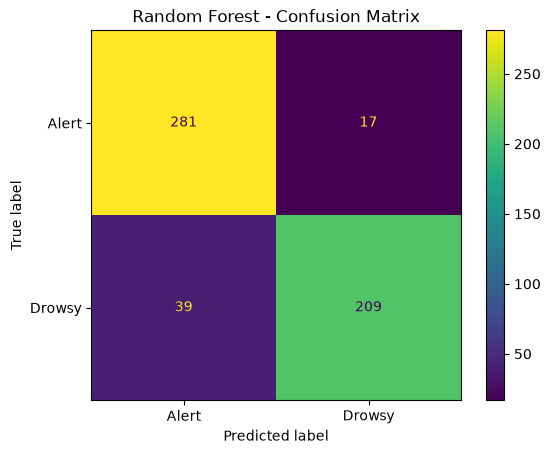

Saved model to: C:\Users\x1605\Mini Project\models\drowsiness_model.joblib


In [12]:
if dataset.empty:
    print("Collect data first, then rerun this cell.")
else:
    required_columns = FEATURE_COLUMNS + ["label"]
    missing = [column for column in required_columns if column not in dataset.columns]
    if missing:
        raise ValueError(f"Dataset is missing columns: {missing}")

    clean = dataset[required_columns].copy()
    clean[FEATURE_COLUMNS] = clean[FEATURE_COLUMNS].apply(pd.to_numeric, errors="coerce")
    clean = clean.replace([np.inf, -np.inf], np.nan).dropna()
    clean["label"] = clean["label"].astype(str)

    class_counts = clean["label"].value_counts()
    print("Usable rows:", len(clean))
    print("Class counts:\n", class_counts)

    if len(class_counts) < 2 or class_counts.min() < 2:
        print("Collect more samples for both Alert and Drowsy (at least 2 per class; more is better).")
    else:
        X = clean[FEATURE_COLUMNS]
        y = clean["label"]
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.25, random_state=42, stratify=y
        )

        model = RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            min_samples_leaf=2,
        )
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        print(f"Test accuracy (initial estimate): {accuracy_score(y_test, y_pred):.3f}")
        print("\nClassification report:\n")
        print(classification_report(y_test, y_pred, zero_division=0))

        ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
        plt.title("Random Forest - Confusion Matrix")
        plt.show()

        bundle = {"model": model, "feature_columns": FEATURE_COLUMNS}
        joblib.dump(bundle, MODEL_PATH)
        print("Saved model to:", MODEL_PATH.resolve())

## 8. Run real-time drowsiness detection

This cell loads the trained classifier and combines its prediction with a safety rule for prolonged eye closure. The visual warning and alarm are for demonstration only. Press **Q** in the OpenCV window to stop. The system appends timestamped drowsiness events to `logs/drowsiness_events.csv`.

In [13]:
def _play_alarm_beep():
    """Non-blocking best-effort beep (Windows beep; terminal bell fallback)."""
    try:
        if sys.platform.startswith("win"):
            import winsound
            winsound.Beep(1400, 450)
        else:
            print("", end="", flush=True)
    except Exception:
        pass


def run_detection(camera_index=0):
    if not MODEL_PATH.exists():
        print("Trained model not found. First collect data and run the training cell.")
        return

    bundle = joblib.load(MODEL_PATH)
    model = bundle["model"]
    model_features = bundle["feature_columns"]

    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        cap = cv2.VideoCapture(camera_index, cv2.CAP_V4L2)
    if not cap.isOpened():
        cap.release()
        print("Could not open webcam. Try camera_index=1 or close other camera apps.")
        return

    eye_closed_since = None
    last_alarm_time = 0.0
    last_drowsy_time = 0.0
    previous_drowsy = False
    events = []

    try:
        with UniversalFaceMesh() as face_mesh:
            while True:
                ok, frame = cap.read()
                if not ok:
                    print("Could not read camera frame.")
                    break

                frame = cv2.flip(frame, 1)
                rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                face_landmarks = face_mesh.process(rgb)
                now = time.monotonic()
                drowsy = False
                status = "Face not detected"
                color = (0, 255, 255)

                if face_landmarks:
                    metrics = extract_face_metrics(face_landmarks)
                    if metrics["avg_ear"] < EAR_THRESHOLD:
                        if eye_closed_since is None:
                            eye_closed_since = now
                        closed_seconds = now - eye_closed_since
                    else:
                        eye_closed_since = None
                        closed_seconds = 0.0

                    features = {**metrics, "eye_closed_seconds": float(closed_seconds)}
                    model_input = pd.DataFrame([[features[c] for c in model_features]],
                                                columns=model_features)
                    ml_prediction = str(model.predict(model_input)[0])

                    # Hybrid decision: sustained eye closure is a direct alert trigger.
                    # The ML prediction can also support a warning for very low EAR or a wide-open mouth.
                    prolonged_closure = closed_seconds >= CLOSED_EYE_ALARM_SECONDS
                    ml_support = (ml_prediction.lower() == "drowsy" and
                                  (closed_seconds >= 0.8 or metrics["mar"] >= 0.65))
                    drowsy = bool(prolonged_closure or ml_support)

                    if drowsy:
                        status = f"DROWSY WARNING | ML: {ml_prediction}"
                        color = (0, 0, 255)
                    else:
                        status = f"ALERT | ML: {ml_prediction}"
                        color = (0, 200, 0)

                    cv2.putText(frame, f"EAR: {metrics['avg_ear']:.3f}  MAR: {metrics['mar']:.3f}",
                                (15, 65), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 2)
                    cv2.putText(frame, f"Eye closure: {closed_seconds:.1f}s", (15, 95),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 2)
                else:
                    eye_closed_since = None

                cv2.putText(frame, status, (15, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
                cv2.putText(frame, "Press Q to stop", (15, frame.shape[0] - 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
                cv2.imshow("Driver Drowsiness Detection", frame)

                # Save one event when the system changes into a drowsy state.
                if drowsy and not previous_drowsy:
                    events.append({
                        "timestamp": datetime.now().isoformat(timespec="seconds"),
                        "event": "Drowsy warning",
                        "ml_prediction": ml_prediction if face_landmarks else "Unknown",
                    })
                previous_drowsy = drowsy

                # Play song while drowsiness warning is active
                if drowsy:
                    last_drowsy_time = now
                    if not pygame.mixer.music.get_busy():
                        pygame.mixer.music.play(-1)

                elif pygame.mixer.music.get_busy() and (now - last_drowsy_time) >= 1.5:
                    pygame.mixer.music.stop()

                if cv2.waitKey(1) & 0xFF == ord("q"):
                    break
    finally:
        pygame.mixer.music.stop()
        cap.release()
        cv2.destroyAllWindows()

    if events:
        events_df = pd.DataFrame(events)
        if EVENT_LOG_PATH.exists():
            old_events = pd.read_csv(EVENT_LOG_PATH)
            events_df = pd.concat([old_events, events_df], ignore_index=True)
        events_df.to_csv(EVENT_LOG_PATH, index=False)
        print(f"Saved {len(events)} event(s) to {EVENT_LOG_PATH.resolve()}")
        display(events_df.tail())
    else:
        print("Stopped. No new drowsiness events were logged.")

# Run live detection:
# run_detection(camera_index=0)

### Start the detector

Run the cell below after your model is saved. Focus the OpenCV window and press **Q** to exit.

In [15]:
run_detection(camera_index=0)

Saved 2 event(s) to C:\Users\x1605\Mini Project\logs\drowsiness_events.csv


,timestamp,event,ml_prediction
18,2026-10-28T23:01:14,Drowsy warning,Drowsy
19,2026-10-28T23:01:14,Drowsy warning,Drowsy
20,2026-10-28T23:01:18,Drowsy warning,Drowsy
21,2026-10-28T23:09:11,Drowsy warning,Drowsy
22,2026-10-28T23:09:48,Drowsy warning,Drowsy


## 9. Project notes and limitations

- Face landmarks are produced by MediaPipe's pretrained model; the Random Forest in this notebook is the model you train from your collected labels.
- Collect both labels carefully. Label examples honestly and avoid collecting only a few seconds of near-identical frames.
- Test in different lighting, with and without glasses if applicable, and across multiple people only with their consent.
- A yawn, blink, or eye closure by itself does not prove a person is dangerously sleepy. This prototype can produce false positives and false negatives.
- For a stronger evaluation, collect multiple sessions and split the train/test data by session or person rather than randomly splitting adjacent video frames.
- Never rely on this prototype as a real vehicle safety device.

In [31]:
import sys
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import sklearn
import joblib

print("Python:", sys.version)
print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("NumPy:", np.__version__)

print("\nAll libraries imported successfully!")

Python: 3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]
OpenCV: 4.10.0
MediaPipe: 0.10.21
NumPy: 1.26.4

All libraries imported successfully!


In [32]:
from pathlib import Path
import pandas as pd

# Project folders
base_dir = Path.cwd()

model_path = base_dir / "models" / "drowsiness_model.joblib"
log_path = base_dir / "logs" / "drowsiness_events.csv"

# Check saved files
print("Trained model exists:", model_path.exists())
print("Model location:", model_path)

print("\nEvent log exists:", log_path.exists())
print("Log location:", log_path)

# Display recorded events
if log_path.exists():
    events = pd.read_csv(log_path)
    display(events.tail(10))

Trained model exists: True
Model location: C:\Users\x1605\Mini Project\models\drowsiness_model.joblib

Event log exists: True
Log location: C:\Users\x1605\Mini Project\logs\drowsiness_events.csv


,timestamp,event,ml_prediction
5,2026-10-28T09:50:43,Drowsy warning,Drowsy
6,2026-10-28T09:50:55,Drowsy warning,Drowsy
7,2026-10-28T10:05:48,Drowsy warning,Drowsy
8,2026-10-28T10:06:05,Drowsy warning,Drowsy
9,2026-10-28T10:06:17,Drowsy warning,Drowsy
10,2026-10-28T10:07:53,Drowsy warning,Drowsy
11,2026-10-28T10:24:02,Drowsy warning,Drowsy
12,2026-10-28T10:24:05,Drowsy warning,Drowsy
13,2026-10-28T10:35:34,Drowsy warning,Drowsy
14,2026-10-28T10:35:38,Drowsy warning,Drowsy


In [33]:
from pathlib import Path

print("Project folder:", Path.cwd())

Project folder: C:\Users\x1605\Mini Project


In [34]:
from pathlib import Path
import pygame

# Locate the song
song_path = Path.cwd() / "funny_munni.mp3"

print("Song file exists:", song_path.exists())
print("Song location:", song_path)

# Initialize audio
if not pygame.mixer.get_init():
    pygame.mixer.init()

# Load and play the song
pygame.mixer.music.stop()
pygame.mixer.music.load(str(song_path))
pygame.mixer.music.play(-1)

print("Is song playing:", pygame.mixer.music.get_busy())

Song file exists: True
Song location: C:\Users\x1605\Mini Project\funny_munni.mp3
Is song playing: True


In [16]:
from pathlib import Path

print("Current folder:", Path.cwd())

for name, path in {
    "Dataset": DATA_PATH,
    "Trained model": MODEL_PATH,
    "Event log": EVENT_LOG_PATH,
    "Song": Path.cwd() / "funny_munni.mp3"
}.items():
    print(f"{name}: {path}")
    print("Exists:", path.exists())
    print("-" * 40)

Current folder: C:\Users\x1605\Mini Project
Dataset: C:\Users\x1605\Mini Project\data\features.csv
Exists: True
----------------------------------------
Trained model: C:\Users\x1605\Mini Project\models\drowsiness_model.joblib
Exists: True
----------------------------------------
Event log: C:\Users\x1605\Mini Project\logs\drowsiness_events.csv
Exists: True
----------------------------------------
Song: C:\Users\x1605\Mini Project\funny_munni.mp3
Exists: True
----------------------------------------
